[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sampriti-sr/MLP_Course/blob/kshitij-variant/docs/recsys/05-factorisation.ipynb)

# Matrix Factorisation: Learning a Taste Vector per User and per Movie

<div class="admonition info">
<p class="admonition-title">What you will be able to do after this page</p>
<ul>
<li>Fit PureSVD, a biased explicit factorisation and an implicit-feedback ALS model, and say what each one optimises.</li>
<li>Choose the number of factors, the regularisation and the confidence weight on a validation split.</li>
<li>Show that the <em>training signal</em> (which interactions count) can matter more than the algorithm.</li>
<li>Quantify run-to-run variation from random initialisation before reporting a difference between models.</li>
</ul>
</div>

**Prerequisites:** [Neighbourhood methods](04-neighbourhood.ipynb). **Dataset:** MovieLens small. **Time:** about 45 minutes.

## The situation

Neighbourhood models compare users or movies one pair at a time. **Matrix factorisation** compresses the whole ratings matrix into a handful of numbers per user and per movie, a *taste vector*, so that the score of a movie for a user is a dot product. Two questions decide whether that pays off: *what are we asking the factors to reproduce* (the stars, or just who rated what), and *how many factors can 100,000 ratings support*? This page answers both with measurements.

In [1]:
try:
    import mlp_data
except ImportError:  # e.g. a fresh Colab runtime
    %pip install -q "mlp-course @ git+https://github.com/sampriti-sr/MLP_Course@kshitij-variant"
    import mlp_data

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlp_data import load_movielens, recsys as rs, style

style.apply()
pd.set_option("display.width", 120)
pd.set_option("display.float_format", "{:,.4f}".format)

## Maths ↔ code

With $f$ factors, a user has a vector $p_u \in \mathbb{R}^f$ and a movie $q_i \in \mathbb{R}^f$, and the score is $p_u \cdot q_i$ (plus offsets in the explicit model).

- **PureSVD:** the best rank-$f$ approximation of the 0/1 matrix, $X \approx U_f \Sigma_f V_f^\top$ (`rs.pure_svd`, which uses `scipy.sparse.linalg.svds`).
- **Biased explicit MF:** minimise $\sum_{(u,i)\ \text{observed}} (r_{ui} - \mu - b_u - b_i - p_u\cdot q_i)^2 + \lambda\,(\ldots)$ over the *observed* ratings only, by alternating least squares (`rs.als_explicit`).
- **Implicit ALS** (Hu, Koren, Volinsky): every cell is a 0/1 *preference* $p_{ui}$ with *confidence* $c_{ui} = 1 + \alpha\,x_{ui}$; minimise $\sum_{\text{all } (u,i)} c_{ui}\,(p_{ui} - p_u\cdot q_i)^2 + \lambda(\ldots)$. It uses the *missing* cells too, as weak evidence of "not wanted" (`rs.als_implicit`).
- **ALS** alternates: fix all $q_i$ and solve a small least-squares problem for each $p_u$ in closed form, then fix the $p_u$ and solve for each $q_i$. No gradient, no learning rate.

## 0. Setup

In [2]:
ratings = load_movielens().ratings
movies = load_movielens().movies
title = movies.set_index("movieId")["title"]

task = rs.make_task(ratings)
val = rs.make_task(task.train, index=task.index)
n_users, n_items = task.X.shape

def ndcg(scores, t):
    return rs.evaluate(scores, t.B, t.relevant)["ndcg"].mean()

def per_user(scores):
    return rs.evaluate(scores, task.B, task.relevant)["ndcg"]

index_of_user = pd.Series(range(n_users), index=task.index.users)
index_of_item = pd.Series(range(n_items), index=task.index.items)

def rmse(predicted, held_out):
    r, c = held_out.userId.map(index_of_user).to_numpy(), held_out.movieId.map(index_of_item).to_numpy()
    return float(np.sqrt(np.mean((predicted[r, c] - held_out.rating.to_numpy()) ** 2)))

## 1. PureSVD, and how many factors the data can support

The simplest factorisation: take the SVD of the 0/1 training matrix, keep the top $f$ components and use the reconstruction as the score. There is one knob, $f$. Tune it on the validation split.

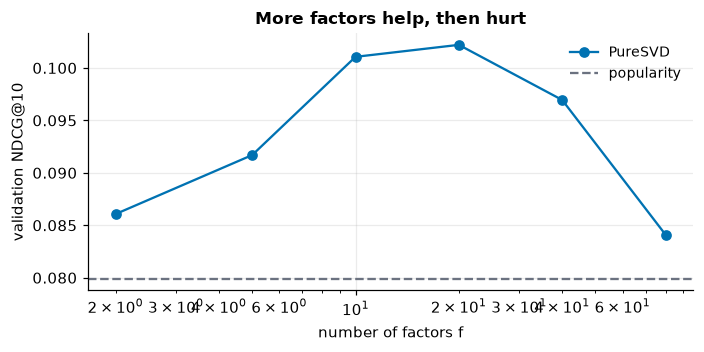

,2,5,10,20,40,80
validation NDCG@10,0.0861,0.0917,0.1011,0.1022,0.0969,0.0841


In [3]:
factor_counts = (2, 5, 10, 20, 40, 80)
svd_curve = pd.Series({f: ndcg(rs.pure_svd(val.B, f), val) for f in factor_counts}, name="validation NDCG@10")
best_f_svd = svd_curve.idxmax()

fig, ax = plt.subplots(figsize=(6.5, 3.3))
ax.plot(svd_curve.index, svd_curve.values, marker="o", color=style.BLUE, label="PureSVD")
ax.axhline(ndcg(rs.broadcast(rs.popularity(val.B), n_users), val), color=style.GREY, ls="--", label="popularity")
ax.set(xscale="log", xlabel="number of factors f", ylabel="validation NDCG@10", title="More factors help, then hurt"); ax.legend()
plt.tight_layout(); plt.show()
assert best_f_svd in (10, 20) and svd_curve.iloc[-1] < svd_curve.max() - 0.01      # guards the reading below
svd_curve.to_frame().T

The curve rises to a peak at **20 factors** (0.1022) and then falls: 40 factors score 0.097 and 80 factors 0.084, barely above popularity (0.0799). Past a moderate rank the reconstruction starts copying the training matrix, noise included, and a copy of "what you already rated" says nothing about the next thing you will like. The number of factors is a capacity knob, and the data (a few thousand movies' worth of signal from 610 users) supports a small one.

## 2. Explicit factorisation: the stars, with offsets

Now factorise the *ratings*, using only the cells that were actually rated (`rs.als_explicit`), on top of the user and movie offsets of page 4. Score it the way a rating model should be scored, by RMSE, and also by what happens when you rank with it:

In [4]:
mu, b_user, b_item = rs.bias_baseline(val.X)
baseline_rmse = rmse(mu + b_user[:, None] + b_item[None, :], val.test)

grid = {}
for f in (5, 20):
    for reg in (0.05, 0.2, 0.5, 1.0):
        scores = rs.als_explicit(val.X, factors=f, reg=reg, iters=15).scores()
        grid[(f, reg)] = {"validation RMSE": rmse(scores, val.test), "validation NDCG@10 of the ranking": ndcg(scores, val)}
explicit = pd.DataFrame(grid).T.rename_axis(["factors", "regularisation"])
print(f"validation RMSE of the bias baseline (no factors): {baseline_rmse:.4f}")
best_explicit = explicit["validation RMSE"].idxmin()
print(f"best explicit model on validation: factors = {best_explicit[0]}, regularisation = {best_explicit[1]}")

best_scores = rs.als_explicit(val.X, factors=best_explicit[0], reg=best_explicit[1], iters=15).scores()
val_counts = np.asarray(val.B.sum(axis=0)).ravel()
behind_explicit = np.median(val_counts[rs.top_k(best_scores, val.B, k=10)])
behind_popular = np.median(val_counts[rs.top_k(rs.broadcast(rs.popularity(val.B), n_users), val.B, k=10)])
print(f"median number of training ratings behind a recommended movie: {behind_explicit:.0f} for the best explicit model, {behind_popular:.0f} for popularity")
assert explicit["validation RMSE"].min() < baseline_rmse and explicit["validation NDCG@10 of the ranking"].max() < 0.02 and behind_explicit < 10
explicit

validation RMSE of the bias baseline (no factors): 0.8861
best explicit model on validation: factors = 20, regularisation = 0.2


median number of training ratings behind a recommended movie: 1 for the best explicit model, 175 for popularity


validation RMSE  validation NDCG@10 of the ranking
factors regularisation                                                    
5       0.0500                   0.9440                             0.0012
        0.2000                   0.8826                             0.0007
        0.5000                   0.8958                             0.0004
        1.0000                   0.9099                             0.0004
20      0.0500                   0.9291                             0.0120
        0.2000                   0.8798                             0.0007
        0.5000                   0.8958                             0.0004
        1.0000                   0.9099                             0.0004

Two readings. **The factors add almost nothing to the offsets:** the best explicit model has a validation RMSE of 0.880 against 0.886 for the plain bias baseline, a gain of 0.006 stars, and regularisation matters far more than the number of factors (0.05 overfits to RMSE 0.93 to 0.94, 1.0 underfits to 0.91). **And it cannot rank:** its NDCG is between 0.0004 and 0.012 for every setting, at the level of a random list. The last line shows why: the median movie in its top ten has **one** training rating, against 201 for the popularity list. It is trained only on cells that were rated, never told that *which* movies get rated is informative, and it lifts movies with a single enthusiastic rating to the top.

## 3. Implicit ALS, and the question of what counts as a signal

Implicit ALS factorises the whole 0/1 matrix, weighting observed cells by a confidence $1 + \alpha x_{ui}$. Which interactions go in as $x_{ui}$? On this data we have four candidates, and the choice is not obvious:

| Training signal | What goes in |
|---|---|
| any rating | 1 for every movie the user rated |
| liked only | 1 for movies rated 4 stars or more, nothing for the rest |
| stars as confidence | the rating divided by 5, so a 5 counts more than a 3 |
| positive deviation | how far above the user's own mean the rating is, kept only if positive |

Tune each on the validation split (factors, regularisation, confidence weight $\alpha$), then compare the best of each.

In [5]:
def training_signals(t):
    X = t.X.copy()
    liked = X.copy(); liked.data = (liked.data >= 4).astype(np.float32); liked.eliminate_zeros()
    stars = X.copy(); stars.data = stars.data / 5.0
    centred, _ = rs.centre_users(X)
    deviation = centred.copy(); deviation.data = np.maximum(deviation.data, 0); deviation.eliminate_zeros()
    return {"any rating": t.B, "liked only (4 stars or more)": liked, "stars as confidence": stars, "positive deviation from user mean": deviation}

import itertools
rows = []
start = time.perf_counter()
for name, signal in training_signals(val).items():
    for f, reg, alpha in itertools.product((16, 32), (10, 50), (1, 5)):
        model = rs.als_implicit(signal, factors=f, reg=reg, alpha=alpha, iters=10, seed=0)
        rows.append({"signal": name, "factors": f, "reg": reg, "alpha": alpha, "validation NDCG@10": ndcg(model.scores(), val)})
tuning = pd.DataFrame(rows)
print(f"{len(rows)} models fitted in {time.perf_counter() - start:.0f} s")
best = tuning.loc[tuning.groupby("signal")["validation NDCG@10"].idxmax()].set_index("signal").sort_values("validation NDCG@10", ascending=False)
assert best.index[0] in ("positive deviation from user mean", "liked only (4 stars or more)")       # guards the reading below
assert best.loc["liked only (4 stars or more)", "validation NDCG@10"] > best.loc["any rating", "validation NDCG@10"] + 0.015
best

32 models fitted in 42 s


,factors,reg,alpha,validation NDCG@10
signal,,,,
positive deviation from user mean,32,10,1,0.1319
liked only (4 stars or more),32,10,1,0.1313
stars as confidence,32,50,5,0.1125
any rating,16,10,1,0.1058


Keeping **only the likes** lifts validation NDCG from 0.106 to **0.131**, a gain of 0.025: the largest single improvement on this page, larger than any gain from tuning factors or changing algorithm. The reason is a mismatch. The test hits are *liked* movies, but the "any rating" signal also teaches the model about movies people rated 1 or 2 stars (about half of all ratings are below 4 stars), so it learns "what gets watched", not "what gets enjoyed". Using the stars as confidence (rating / 5) helps only a little (0.1125), because a 2-star rating still counts as positive evidence. "Liked only" and "positive deviation from the user's mean" tie (0.1313 against 0.1319), and we continue with the simpler **liked only**. Its best settings are 32 factors, regularisation 10 and a low confidence weight of 1.

## 4. What did the factors learn?

A factor model has no explicit notion of "genre", yet movies that the same kind of person likes end up close together. Check by eye: take the **liked-only** model, fit on the training split, and list each movie's nearest neighbours by cosine similarity of their factor vectors (movies with fewer than 20 training ratings are skipped, because their factors are noise).

In [6]:
chosen = best.loc["liked only (4 stars or more)"]
signal_task = training_signals(task)["liked only (4 stars or more)"]
model = rs.als_implicit(signal_task, factors=int(chosen["factors"]), reg=chosen["reg"], alpha=chosen["alpha"], iters=10, seed=0)

item_vectors = model.item_f
unit = item_vectors / np.maximum(np.linalg.norm(item_vectors, axis=1, keepdims=True), 1e-9)
n_ratings = np.asarray(task.B.sum(axis=0)).ravel()

def nearest(prefix, n=5):
    movie_id = movies.loc[movies["title"].str.startswith(prefix), "movieId"].iloc[0]
    j = int(np.flatnonzero(task.index.items == movie_id)[0])
    similarity = unit @ unit[j]
    similarity[n_ratings < 20] = -1
    order = np.argsort(-similarity)[1:n + 1]
    return [title[task.index.items[i]].split(" (")[0] for i in order]

pd.DataFrame({name: nearest(name) for name in ["Toy Story (1995)", "Godfather, The (1972)", "Alien (1979)", "Pulp Fiction"]},
             index=[f"neighbour {k}" for k in range(1, 6)]).T

,neighbour 1,neighbour 2,neighbour 3,neighbour 4,neighbour 5
Toy Story (1995),Toy Story 2,"Birdcage, The",Aladdin,"Hunchback of Notre Dame, The",Babe
"Godfather, The (1972)","Godfather: Part II, The",Goodfellas,Reservoir Dogs,One Flew Over the Cuckoo's Nest,Apocalypse Now
Alien (1979),Aliens,"Terminator, The",Blade Runner,Jaws,Star Wars: Episode V - The Empire Strikes Back
Pulp Fiction,"Silence of the Lambs, The",Seven,"Usual Suspects, The","Shawshank Redemption, The",Braveheart


Nobody told the model about genres, sequels or directors, yet Toy Story's neighbours are *Toy Story 2*, *Aladdin*, *The Hunchback of Notre Dame* and *Babe*; The Godfather's are *Part II*, *Goodfellas*, *Reservoir Dogs* and *Apocalypse Now*; Alien's are *Aliens*, *The Terminator*, *Blade Runner* and *Jaws*. The factors recovered "kinds of movie" from nothing but who liked what. The list also shows the model's limit: it knows the kind of movie, not *why* you would watch it.

## 5. The test set, once

Everything is fixed. For a fair table, every model family gets the same two training signals, *any rating* and *liked only*, with its own settings tuned on validation (the item-based neighbours: $k$ and shrinkage; PureSVD: the number of factors; implicit ALS: the settings found above). ALS starts from random numbers, so it is trained from five different seeds and its per-user scores are averaged.

In [7]:
val_signals, test_signals = training_signals(val), training_signals(task)

def tune_knn(signal):
    grid = {(k, lam): ndcg(rs.item_knn_scores(signal, rs.item_similarity(signal, k=k, shrink=lam)), val)
            for k in (50, 100) for lam in (10, 50)}
    return max(grid, key=grid.get)

def tune_svd(signal):
    return max((10, 20, 40), key=lambda f: ndcg(rs.pure_svd(signal, f), val))

test_scores = {"popularity": per_user(rs.broadcast(rs.popularity(task.B), n_users))}
centred, _ = rs.centre_users(task.X)
test_scores["item-item, centred ratings (page 4)"] = per_user(
    rs.predict_ratings_knn(task.X, rs.item_similarity(centred, k=100, shrink=50), axis="item", shrink=100))

seed_means = {}
for name in ("any rating", "liked only (4 stars or more)"):
    sv, st = val_signals[name], test_signals[name]
    k, lam = tune_knn(sv)
    f_svd = tune_svd(sv)
    row = best.loc[name]
    test_scores[f"item-item neighbours, {name}"] = per_user(rs.item_knn_scores(st, rs.item_similarity(st, k=k, shrink=lam)))
    test_scores[f"PureSVD, {name}"] = per_user(rs.pure_svd(st, f_svd))
    per_seed = [per_user(rs.als_implicit(st, factors=int(row["factors"]), reg=row["reg"], alpha=row["alpha"], iters=10, seed=seed).scores())
                for seed in range(5)]
    seed_means[name] = [s.mean() for s in per_seed]
    test_scores[f"implicit ALS, {name}"] = pd.concat(per_seed, axis=1).mean(axis=1)

reference = test_scores["popularity"]
best_neighbour = test_scores["item-item, centred ratings (page 4)"]
rows = {}
for name, s in test_scores.items():
    vs_pop = rs.paired_difference(s, reference)
    vs_nb = rs.paired_difference(s, best_neighbour)
    rows[name] = {"test NDCG@10": s.mean(),
                  "vs popularity": "" if name == "popularity" else f"{vs_pop['diff']:+.4f} [{vs_pop['lo']:+.4f}, {vs_pop['hi']:+.4f}]",
                  "vs page-4 model": "" if s is best_neighbour else f"{vs_nb['diff']:+.4f} [{vs_nb['lo']:+.4f}, {vs_nb['hi']:+.4f}]"}
table = pd.DataFrame(rows).T
for name in ("item-item neighbours", "PureSVD", "implicit ALS"):                                  # guards the reading below
    assert rs.paired_difference(test_scores[f"{name}, any rating"], best_neighbour)["hi"] < 0
    assert rs.paired_difference(test_scores[f"{name}, liked only (4 stars or more)"], best_neighbour)["lo"] < 0
table

,test NDCG@10,vs popularity,vs page-4 model
popularity,0.0743,,"-0.0372 [-0.0496, -0.0248]"
"item-item, centred ratings (page 4)",0.1115,"+0.0372 [+0.0248, +0.0496]",
"item-item neighbours, any rating",0.0913,"+0.0169 [+0.0053, +0.0286]","-0.0203 [-0.0320, -0.0086]"
"PureSVD, any rating",0.0887,"+0.0143 [+0.0024, +0.0262]","-0.0229 [-0.0353, -0.0104]"
"implicit ALS, any rating",0.0914,"+0.0171 [+0.0059, +0.0283]","-0.0201 [-0.0321, -0.0081]"
"item-item neighbours, liked only (4 stars or more)",0.1153,"+0.0410 [+0.0292, +0.0528]","+0.0038 [-0.0057, +0.0132]"
"PureSVD, liked only (4 stars or more)",0.1157,"+0.0414 [+0.0295, +0.0533]","+0.0042 [-0.0068, +0.0152]"
"implicit ALS, liked only (4 stars or more)",0.1208,"+0.0465 [+0.0348, +0.0581]","+0.0092 [-0.0007, +0.0192]"


Three readings, all from the paired intervals.

1. **Within a training signal the algorithms tie.** With any rating the three models score 0.089 to 0.091, with likes only 0.115 to 0.121; none of the gaps within a group is distinguishable from noise.
2. **The signal moves every algorithm by 0.025 to 0.030**: item-item 0.0913 to 0.1153, PureSVD 0.0887 to 0.1157, implicit ALS 0.0914 to 0.1208. With any rating, all three are reliably *below* the centred-ratings model of page 4 (intervals under zero); with likes only they are level with it (intervals contain zero).
3. The best model, **implicit ALS on the likes (0.1208), is 63% above popularity** (+0.047, interval [+0.035, +0.058]) and +0.009 above the page-4 neighbourhood model, an interval of [-0.001, +0.019] that cannot rule out a tie.

So what separated the models on this data was *what they were trained on*, not *how*.

## 6. What goes wrong

**Run-to-run noise.** ALS starts from random numbers, so two runs differ. Before believing a gap between two models, look at how much one model differs from *itself*:

In [8]:
noise = pd.DataFrame({name: pd.Series(v).describe()[["mean", "min", "max"]] for name, v in seed_means.items()}).T
noise["spread (max - min)"] = noise["max"] - noise["min"]
gain = noise.loc["liked only (4 stars or more)", "mean"] - noise.loc["any rating", "mean"]
assert gain > 3 * noise["spread (max - min)"].max()
noise.rename_axis("ALS training signal")

,mean,min,max,spread (max - min)
ALS training signal,,,,
any rating,0.0914,0.0886,0.0946,0.0060
liked only (4 stars or more),0.1208,0.1187,0.1225,0.0039


A single ALS run differs from the average of its own five seeds by up to about 0.003 (any rating: 0.0886 to 0.0946; likes only: 0.1187 to 0.1225). That is the size of several of the gaps between algorithms above, which is why the table averages over seeds. The effect of the training signal (0.030) is five to eight times the seed-to-seed spread, so it is not noise; an algorithm gap of 0.003 would be.

<div class="admonition warning">
<p class="admonition-title">Watch out</p>
<p>Three things can each fake a win for a factor model: a single random seed, tuning on the test set, and a training signal that is easier for it than for its competitor. Fix the signal for every model, tune on validation, average over seeds, and report a paired interval.</p>
</div>

## Decision guide

| Situation | Use | Why |
|---|---|---|
| Ranking, with ratings available | **Train on the likes** (or centred ratings), whichever algorithm | The training signal mattered more here than the algorithm |
| Only implicit events (clicks, purchases) | Implicit ALS, tune $\alpha$ | It uses the unobserved cells as weak evidence |
| You must predict the star value | Biased explicit MF or just the bias baseline, scored by RMSE | Only worth it if the star value itself is the product |
| Very little data or very sparse items | Item-item with shrinkage | Factors for rarely rated items are noise |
| Millions of users and items | ALS or an approximate-neighbour index | Both scale; dense similarity tables do not |

## Check yourself

<details class="question">
<summary>1. PureSVD scores worse with 80 factors than with 20. A factor model with more capacity should fit better. What is going on?</summary>

With many factors the reconstruction of the training matrix gets close to the matrix itself, including its noise, and a perfect copy of "what you already rated" says nothing about what you would like next. The validation score measures prediction of *new* interactions, so it peaks at a moderate rank and then falls: overfitting, with the factor count as the capacity knob.

</details>

<details class="question">
<summary>2. Why does the explicit model have the best RMSE and a ranking no better than random?</summary>

It is trained to reproduce the star values of *rated* cells and is never asked which movies a user would rate at all. For movies with one or two ratings its predictions come from almost no evidence, and an unusually high prediction is more likely when evidence is thin. The measurement above shows the result: the median movie it recommends has a single training rating.

</details>

## Exercises

<details class="question">
<summary>Exercise 1 (easy): score the liked-only implicit ALS model for the user in row 0 and print the titles of their top 5 unseen movies.</summary>

```python
scores = model.scores()[0].copy()
scores[task.B[0].nonzero()[1]] = -np.inf
print([title[task.index.items[j]] for j in np.argsort(-scores)[:5]])
```

The list is Die Hard, Aladdin, The Godfather, Terminator 2 and The Godfather: Part II. As on page 3, hide the user's own movies before reading a list.

</details>

<details class="question">
<summary>Exercise 2 (medium): the training signal "liked only" uses a threshold of 4 stars. Try 3.5 and 4.5 for the implicit ALS model with the settings above. What changes?</summary>

```python
for threshold in (3.5, 4.0, 4.5):
    signal = task.X.copy(); signal.data = (signal.data >= threshold).astype(np.float32); signal.eliminate_zeros()
    m = rs.als_implicit(signal, factors=int(chosen["factors"]), reg=chosen["reg"], alpha=chosen["alpha"], iters=10, seed=0)
    print(threshold, per_user(m.scores()).mean())
```

Test NDCG is 0.1159 at 3.5, **0.1209 at 4.0** and 0.1106 at 4.5. The best threshold is the one that matches the definition of a hit; a looser signal (more, but weaker, positives) and a stricter one (fewer positives, 17,572 instead of 39,222) both lose 0.005 to 0.010.

</details>

<details class="question">
<summary>Exercise 3 (hard): how does the validation NDCG of liked-only ALS change with the number of ALS iterations (2, 5, 10, 20)?</summary>

```python
for iters in (2, 5, 10, 20):
    m = rs.als_implicit(val_signals["liked only (4 stars or more)"], factors=int(chosen["factors"]), reg=chosen["reg"], alpha=chosen["alpha"], iters=iters, seed=0)
    print(iters, ndcg(m.scores(), val))
```

Validation NDCG is 0.1206 after 2 iterations, 0.1278 after 5, 0.1313 after 10 and 0.1317 after 20: the model has essentially converged by 10. More iterations would be wasted compute; what limits the model now is its regularisation and the amount of data, not training time.

</details>

## Recap

- **PureSVD, explicit MF and implicit ALS** optimise three different things; only the implicit one is designed for ranking.
- **Factors overfit**: the validation curve peaks at a moderate rank and falls.
- The **explicit** model wins on RMSE and ranks like a random list.
- The **training signal** (liked only) was worth about 0.03 NDCG, more than the choice among SVD, ALS and neighbours, which tie.
- **Seeds matter**: average over several, and look at a model's spread against itself before reading a gap between two models.